# PEMFC Fault Diagnostics — Dynamic Fault Generation (Phase 2, Task 3)
David Pinero-Jacome | CMU ECE

---

## ⚠️ Read before any figure below

This notebook's two halves rest on **different foundations**, and they must not
be read as equally validated.

| | status |
|---|---|
| **Healthy baseline** | Adopted logistic radial family at **18×18**, grounded in the cross-session real structure finding and checked against real data on four independent axes below. **This is what this notebook validates.** |
| **Fault-state spatial patterns** | Still the **superseded diagonal-gradient interpolation** inherited from notebook 01. **NOT validated output.** Pending **Phase 3b**. |

Notebook 01's fault patterns were designed as *modifications of a diagonal
flow-path gradient* — flooding suppresses the cathode-outlet corner of that
gradient, drying shifts weight along it, starvation collapses it along the
cathode flow path. The healthy baseline has since been replaced with a radial
template (the real cell's structure is radial, not a flow-path gradient:
r = 0.936 against distance-from-centre, reproducing across all four sessions
at r ≥ 0.976).

Rebasing only the interpolation's *start* point without re-examining its
*endpoints* would produce a trajectory between two points never designed to
connect — plausible-looking but unjustified at every intermediate severity.
That rework is **Phase 3b** and is deliberately not done here. See
`docs/synthetic_generator_notes.md` §8.

**Consequence: every fault-state grid in Part 2 is a demonstration that the
machinery runs, not evidence that the spatial pattern is right.**

**Also**: per §9a, every CV(J) figure in this notebook carries its grid size.
A bare CV(J) number from this family is not interpretable — the same cell can
read 0.17 at 4×4 and 0.25 at 18×18.

No classifier or sequence-model work appears here. Validation only.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

# Notebooks launch with cwd = their own directory; repo root is one level up.
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
FIGURES_DIR = os.path.join(PROJECT_ROOT, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
sys.path.insert(0, PROJECT_ROOT)
sys.path.insert(0, os.path.join(PROJECT_ROOT, "scripts"))

from fault_generator import (
    CLASSIFICATION_THRESHOLD, DEFAULT_GRID_SHAPE, FAULT_COLORS,
    HEALTHY_C_RANGE, HEALTHY_R0_RANGE, HEALTHY_W_RANGE,
    generate_labeled_run, logistic_healthy_shape, sample_healthy_params,
)
from load_real_data import load_run

CONFIGS = ("Normal_Flow", "Inverse_Flow", "Inverse_Air_Flow", "Inverse_Hydrogen_Flow")
print("generator default grid shape:", DEFAULT_GRID_SHAPE)
print("adopted family bounds: c", HEALTHY_C_RANGE, " r0", HEALTHY_R0_RANGE, " w", HEALTHY_W_RANGE)

generator default grid shape: (18, 18)
adopted family bounds: c (0.05, 0.6)  r0 (0.25, 0.7)  w (0.04, 0.35)


---
# Part 1 — Healthy baseline validation

This is the notebook's actual job. Four independent checks against real data:
the CV(J) distribution, the resolution scaling direction, spatial
autocorrelation at matched resolution, and the radius-binned profile shape.

## 1.1 Real reference: CV(J) at both resolutions, all four sessions

Real 18×18 is downsampled to 4×4 by block-averaging with `np.array_split`
([5,5,4,4] per axis — 18 does not divide evenly by 4, so this uses all 324
cells and crops nothing). CV(J) = std/mean is nonlinear, so each timestep is
downsampled *first* and its CV computed after.

In [2]:
def block_average(grid_2d, out_rows, out_cols):
    rg = np.array_split(np.arange(grid_2d.shape[0]), out_rows)
    cg = np.array_split(np.arange(grid_2d.shape[1]), out_cols)
    out = np.empty((out_rows, out_cols))
    for i, r in enumerate(rg):
        for j, c in enumerate(cg):
            out[i, j] = grid_2d[np.ix_(r, c)].mean()
    return out

def lag1_autocorr(g):
    vals = []
    for dr, dc in ((0, 1), (1, 0)):
        a = g[: g.shape[0] - dr, : g.shape[1] - dc].ravel()
        b = g[dr:, dc:].ravel()
        vals.append(np.corrcoef(a, b)[0, 1])
    return float(np.mean(vals))

real = {}
for cfg in CONFIGS:
    run = load_run(cfg, run_type="FC-DLC")
    j = np.abs(run["current_grid"]); n_t = j.shape[0]
    f18 = j.reshape(n_t, -1)
    cv18 = float((f18.std(axis=1) / f18.mean(axis=1)).mean())
    j4 = np.stack([block_average(j[t], 4, 4) for t in range(n_t)])
    f4 = j4.reshape(n_t, -1)
    cv4 = float((f4.std(axis=1) / f4.mean(axis=1)).mean())
    tmpl = (j / f18.mean(axis=1)[:, None, None]).mean(axis=0)
    real[cfg] = dict(cv18=cv18, cv4=cv4, tmpl18=tmpl, tmpl4=block_average(tmpl, 4, 4),
                     ac18=lag1_autocorr(tmpl), ac4=lag1_autocorr(block_average(tmpl, 4, 4)))

print(f"{'configuration':<23}{'CV(J) 4x4':>11}{'CV(J) 18x18':>13}{'ratio':>8}")
for cfg in CONFIGS:
    r = real[cfg]
    print(f"{cfg:<23}{r['cv4']:>11.4f}{r['cv18']:>13.4f}{r['cv18']/r['cv4']:>8.2f}")
REAL_BAND_18 = (min(real[c]['cv18'] for c in CONFIGS), max(real[c]['cv18'] for c in CONFIGS))
REAL_BAND_4  = (min(real[c]['cv4']  for c in CONFIGS), max(real[c]['cv4']  for c in CONFIGS))
print(f"\nreal band @18x18: {REAL_BAND_18[0]:.4f} - {REAL_BAND_18[1]:.4f}")
print(f"real band @ 4x4 : {REAL_BAND_4[0]:.4f} - {REAL_BAND_4[1]:.4f}")

[load_run] Normal_Flow/FC-DLC: 40/18008 CDM rows had no bulk-file match within tolerance=1s


[load_run] Inverse_Flow/FC-DLC: 28/17979 CDM rows had no bulk-file match within tolerance=1s


[load_run] Inverse_Air_Flow/FC-DLC: 31/18007 CDM rows had no bulk-file match within tolerance=1s


[load_run] Inverse_Hydrogen_Flow/FC-DLC: 24/17971 CDM rows had no bulk-file match within tolerance=1s


configuration            CV(J) 4x4  CV(J) 18x18   ratio
Normal_Flow                 0.3344       0.3810    1.14
Inverse_Flow                0.2877       0.3266    1.14
Inverse_Air_Flow            0.3353       0.3812    1.14
Inverse_Hydrogen_Flow       0.2858       0.3247    1.14

real band @18x18: 0.3247 - 0.3812
real band @ 4x4 : 0.2858 - 0.3353


## 1.2 Family CV(J) vs the real band — containment and placement

**Not mean-vs-mean.** A family is deliberately broad; comparing its mean to
the real value measures where the family's centre happens to sit, not whether
the family covers the real cell. The meaningful questions are: is real
*contained*, and *where* does it sit in the span.

In [3]:
N_CELLS = 3000
rng = np.random.default_rng(20260810)
params = [sample_healthy_params(rng) for _ in range(N_CELLS)]
fam18 = np.array([logistic_healthy_shape(p["c"], p["r0"], p["w"], 18, 18).std() for p in params])
fam4  = np.array([logistic_healthy_shape(p["c"], p["r0"], p["w"], 4, 4).std()   for p in params])

def placement(band, fam, label):
    print(f"\n{label}")
    print(f"  family: p5={np.percentile(fam,5):.4f}  median={np.median(fam):.4f}  p95={np.percentile(fam,95):.4f}")
    print(f"  real band: {band[0]:.4f} - {band[1]:.4f}")
    print(f"  CONTAINED: {(fam.min() <= band[0]) and (fam.max() >= band[1])}")
    print(f"  fraction of family BELOW real min: {(fam < band[0]).mean()*100:.0f}%")
    print(f"  fraction of family ABOVE real max: {(fam > band[1]).mean()*100:.0f}%")

placement(REAL_BAND_18, fam18, "=== 18x18 (the generator's native resolution) ===")
for cfg in CONFIGS:
    print(f"    {cfg:<23} real {real[cfg]['cv18']:.4f} -> {(fam18 < real[cfg]['cv18']).mean()*100:3.0f}th percentile of family")
placement(REAL_BAND_4, fam4, "=== 4x4 (for comparison only) ===")


=== 18x18 (the generator's native resolution) ===
  family: p5=0.1245  median=0.2357  p95=0.4552
  real band: 0.3247 - 0.3812
  CONTAINED: True
  fraction of family BELOW real min: 78%
  fraction of family ABOVE real max: 11%
    Normal_Flow             real 0.3810 ->  89th percentile of family
    Inverse_Flow            real 0.3266 ->  79th percentile of family
    Inverse_Air_Flow        real 0.3812 ->  89th percentile of family
    Inverse_Hydrogen_Flow   real 0.3247 ->  78th percentile of family

=== 4x4 (for comparison only) ===
  family: p5=0.1090  median=0.2146  p95=0.3972
  real band: 0.2858 - 0.3353
  CONTAINED: True
  fraction of family BELOW real min: 76%
  fraction of family ABOVE real max: 13%


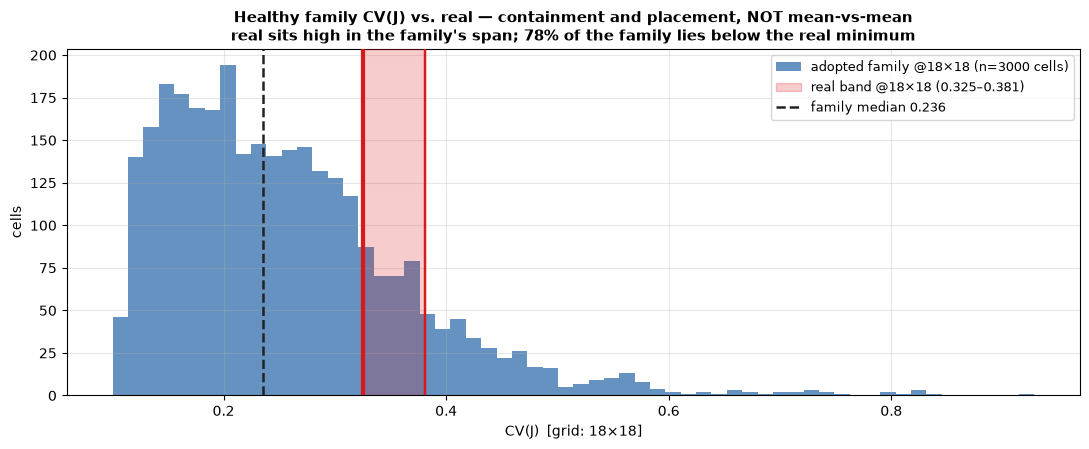

The skew is deliberate and is NOT a defect (docs §7d):
  a more uniform healthy cell has a LOWER CV(J) baseline, so an anomaly
  threshold that must stay quiet across this family has LESS headroom.
  The skew makes false-alarm avoidance HARDER, not easier -- a model quiet
  across this family makes a STRONGER claim than one validated on a family
  centred on the real data. Log-uniform sampling of c was rejected for
  exactly that reason: it would shift mass toward real and weaken the test.


In [4]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.hist(fam18, bins=60, color="#4a7fb5", alpha=0.85, label=f"adopted family @18×18 (n={N_CELLS} cells)")
ax.axvspan(*REAL_BAND_18, color="#d7191c", alpha=0.22, zorder=3,
           label=f"real band @18×18 ({REAL_BAND_18[0]:.3f}–{REAL_BAND_18[1]:.3f})")
for cfg in CONFIGS:
    ax.axvline(real[cfg]["cv18"], color="#d7191c", lw=1.6, zorder=4)
ax.axvline(np.median(fam18), color="#222", ls="--", lw=1.8, zorder=5,
           label=f"family median {np.median(fam18):.3f}")
below = (fam18 < REAL_BAND_18[0]).mean() * 100
ax.set_title("Healthy family CV(J) vs. real — containment and placement, NOT mean-vs-mean\n"
             f"real sits high in the family's span; {below:.0f}% of the family lies below the real minimum",
             fontsize=11, fontweight="bold")
ax.set_xlabel("CV(J)  [grid: 18×18]"); ax.set_ylabel("cells")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "nb03_family_cv_vs_real.png"), dpi=150, bbox_inches="tight")
plt.show()

print("The skew is deliberate and is NOT a defect (docs §7d):")
print("  a more uniform healthy cell has a LOWER CV(J) baseline, so an anomaly")
print("  threshold that must stay quiet across this family has LESS headroom.")
print("  The skew makes false-alarm avoidance HARDER, not easier -- a model quiet")
print("  across this family makes a STRONGER claim than one validated on a family")
print("  centred on the real data. Log-uniform sampling of c was rejected for")
print("  exactly that reason: it would shift mass toward real and weaken the test.")

## 1.3 Resolution scaling direction — a validation point for the form

Real CV(J) rises from 4×4 to 18×18. Does the model reproduce that *direction*?

The superseded Sec. 5 form did not — it moved the opposite way. The adopted
form was selected on **shape** grounds (the real profile inflects and
saturates), so its resolution response is a consequence, not a target.

In [5]:
from fault_generator import generate_healthy_grid_v2, RADIAL_EDGE_RATIO, RADIAL_EDGE_EXPONENT

def superseded_shape(n, edge_ratio=RADIAL_EDGE_RATIO):
    r_, c_ = np.indices((n, n))
    rr = np.sqrt((r_ - (n-1)/2.)**2 + (c_ - (n-1)/2.)**2); rr /= rr.max()
    s = 1.0 + (edge_ratio - 1.0) * rr ** RADIAL_EDGE_EXPONENT
    return s / s.mean()

real_cv4 = np.mean([real[c]["cv4"] for c in CONFIGS]); real_cv18 = np.mean([real[c]["cv18"] for c in CONFIGS])
sup4, sup18 = superseded_shape(4).std(), superseded_shape(18).std()
fitted = {"Normal_Flow": (0.1390,0.4478,0.1123), "Inverse_Flow": (0.2000,0.4273,0.1146),
          "Inverse_Air_Flow": (0.1403,0.4482,0.1131), "Inverse_Hydrogen_Flow": (0.2055,0.4273,0.1142)}
fit4 = np.mean([logistic_healthy_shape(*p, 4, 4).std() for p in fitted.values()])
fit18 = np.mean([logistic_healthy_shape(*p, 18, 18).std() for p in fitted.values()])

print("CV(J), 2x2 -- {real, synthetic} x {4x4, 18x18}\n")
print(f"{'':<42}{'4x4':>9}{'18x18':>9}{'ratio':>9}")
print(f"{'real (4-config mean)':<42}{real_cv4:>9.4f}{real_cv18:>9.4f}{real_cv18/real_cv4:>9.2f}")
print(f"{'synthetic: superseded Sec.5 form':<42}{sup4:>9.4f}{sup18:>9.4f}{sup18/sup4:>9.2f}  <- WRONG SIGN")
print(f"{'synthetic: adopted family (mean of draws)':<42}{fam4.mean():>9.4f}{fam18.mean():>9.4f}{fam18.mean()/fam4.mean():>9.2f}")
print(f"{'synthetic: adopted @ real fitted params':<42}{fit4:>9.4f}{fit18:>9.4f}{fit18/fit4:>9.2f}")
print("\nThe adopted form reproduces real's resolution scaling direction and magnitude.")
print("Honest weighting (docs §7b): one scalar, and not independent of the shape")
print("selection -- but the superseded form also had a radial profile and still got")
print("the sign wrong, so the agreement is not automatic.")

CV(J), 2x2 -- {real, synthetic} x {4x4, 18x18}

                                                4x4    18x18    ratio
real (4-config mean)                         0.3108   0.3534     1.14
synthetic: superseded Sec.5 form             0.2020   0.1709     0.85  <- WRONG SIGN
synthetic: adopted family (mean of draws)    0.2283   0.2554     1.12
synthetic: adopted @ real fitted params      0.3014   0.3415     1.13

The adopted form reproduces real's resolution scaling direction and magnitude.
Honest weighting (docs §7b): one scalar, and not independent of the shape
selection -- but the superseded form also had a radial profile and still got
the sign wrong, so the agreement is not automatic.


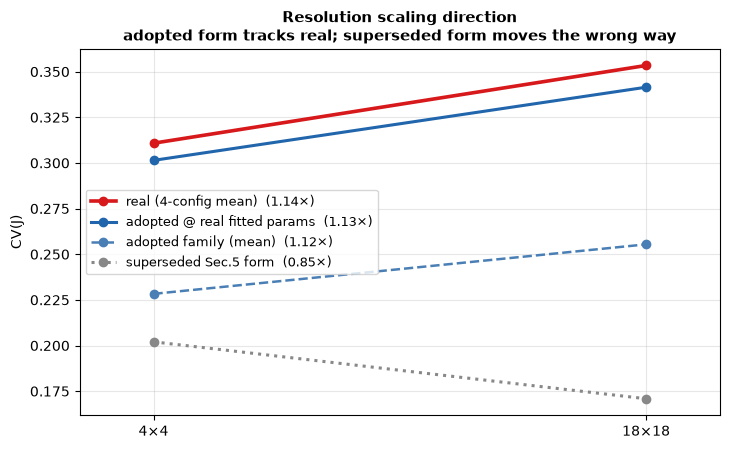

In [6]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
series = [("real (4-config mean)", real_cv4, real_cv18, "#d7191c", "-", 2.6),
          ("adopted @ real fitted params", fit4, fit18, "#2166ac", "-", 2.2),
          ("adopted family (mean)", fam4.mean(), fam18.mean(), "#4a7fb5", "--", 1.8),
          ("superseded Sec.5 form", sup4, sup18, "#888888", ":", 2.2)]
for lab, a, b, col, ls, lw in series:
    ax.plot([0, 1], [a, b], ls, color=col, lw=lw, marker="o", label=f"{lab}  ({b/a:.2f}×)")
ax.set_xticks([0, 1]); ax.set_xticklabels(["4×4", "18×18"])
ax.set_ylabel("CV(J)"); ax.set_xlim(-0.15, 1.15)
ax.set_title("Resolution scaling direction\nadopted form tracks real; superseded form moves the wrong way",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "nb03_resolution_scaling.png"), dpi=150, bbox_inches="tight")
plt.show()

## 1.4 Spatial autocorrelation at matched resolution

Lag-1 autocorrelation is a function of grid spacing, so it must be compared
at matched resolution. Comparing synthetic-4×4 against real-18×18 was the
error that produced an apparent 0.294-vs-0.935 "mismatch" (docs §5f,
superseded).

In [7]:
nf = fitted["Normal_Flow"]
syn_ac4, syn_ac18 = lag1_autocorr(logistic_healthy_shape(*nf, 4, 4)), lag1_autocorr(logistic_healthy_shape(*nf, 18, 18))
real_ac4 = np.mean([real[c]["ac4"] for c in CONFIGS]); real_ac18 = np.mean([real[c]["ac18"] for c in CONFIGS])
print(f"{'':<34}{'4x4':>10}{'18x18':>10}")
print(f"{'real (4-config mean)':<34}{real_ac4:>10.4f}{real_ac18:>10.4f}")
print(f"{'adopted logistic @ NF params':<34}{syn_ac4:>10.4f}{syn_ac18:>10.4f}")
print(f"{'superseded Sec.5 form':<34}{lag1_autocorr(superseded_shape(4)):>10.4f}{lag1_autocorr(superseded_shape(18)):>10.4f}")
print("\nClose at BOTH matched resolutions. Each moves by ~0.6 ACROSS resolutions,")
print("which is what made the original cross-resolution comparison meaningless.")

                                         4x4     18x18
real (4-config mean)                  0.3249    0.9389
adopted logistic @ NF params          0.2793    0.9628
superseded Sec.5 form                 0.2941    0.9545

Close at BOTH matched resolutions. Each moves by ~0.6 ACROSS resolutions,
which is what made the original cross-resolution comparison meaningless.


## 1.5 Radius-binned profile — does the saturation reproduce?

The real radial profile **saturates** toward the edge. A power law has
monotone curvature and cannot inflect, which is why every power-law variant
stalls. The adopted logistic can.

The **radial ceiling** is marked: a *free arbitrary function of radius* (each
shell assigned its own mean, ~40 effective parameters) reaches R² = 0.9416 on
the real template. 5.84% of the template is irreducibly **non-radial** — no
radial form of any complexity can reach it.

> **⚠️ On the superseded form's R² below (0.5836) — this is NOT the 0.7639
> figure recorded in `docs/synthetic_generator_notes.md` §6b, and the two are
> not in conflict.** They answer different questions:
> - **§6b's 0.7639** is that form fitted *at its best possible amplitude* —
>   the most the `p = 2` shape could ever achieve against this template.
> - **0.5836 here** is that form **as the generator actually deployed it**,
>   at `edge_ratio = 2.0`, the value that was in the code.
>
> This notebook compares *deployed configurations*, which is the honest
> comparison for a validation notebook — it shows what the generator really
> produced, not what a best-case refit of a discarded form could have
> produced. A reader cross-referencing §6b should land here, not on an
> apparent contradiction.

In [8]:
M = real["Normal_Flow"]["tmpl18"]
r_, c_ = np.indices((18, 18))
RHO = np.sqrt((r_ - 8.5)**2 + (c_ - 8.5)**2); RHO /= RHO.max()

S_log = logistic_healthy_shape(*nf, 18, 18)
S_sup = superseded_shape(18)

# radial ceiling: free function of radius = shell means
shell_mean = np.zeros_like(M)
for sh in np.unique(np.round(RHO, 6)):
    m = np.isclose(RHO, sh); shell_mean[m] = M[m].mean()
ceiling = 1 - np.sum((M - shell_mean)**2) / np.sum((M - M.mean())**2)
r2_log = 1 - np.sum((S_log - M)**2) / np.sum((M - M.mean())**2)
r2_sup = 1 - np.sum((S_sup - M)**2) / np.sum((M - M.mean())**2)

bins = np.linspace(0, 1, 10); rb = np.digitize(RHO.ravel(), bins)
print(f"{'r/r_max':>9}{'real':>9}{'logistic':>10}{'superseded':>12}")
for b in range(1, 10):
    m = rb == b
    if m.sum():
        print(f"{b/10:>9.2f}{M.ravel()[m].mean():>9.4f}{S_log.ravel()[m].mean():>10.4f}{S_sup.ravel()[m].mean():>12.4f}")
print(f"\nR^2 vs real template (18x18):")
print(f"  adopted logistic (3 params)        : {r2_log:.4f}")
print(f"  superseded Sec.5 form, AS DEPLOYED : {r2_sup:.4f}   (edge_ratio=2.0)")
print(f"      ^ NOT the 0.7639 in docs §6b, which is that form at its BEST")
print(f"        amplitude. Different questions: deployed config vs best-case")
print(f"        refit of a discarded form. See §6b. Not a contradiction.")
print(f"  RADIAL CEILING (free f(radius))    : {ceiling:.4f}   <- irreducible limit for ANY radial form")
print(f"  adopted form reaches {100*r2_log/ceiling:.1f}% of the achievable ceiling")

  r/r_max     real  logistic  superseded
     0.10   0.1484    0.2089      0.7311
     0.20   0.3157    0.2734      0.7513
     0.30   0.3807    0.4111      0.7887
     0.40   0.6379    0.6391      0.8409
     0.50   0.9575    0.9471      0.9180
     0.60   1.1781    1.1892      1.0134
     0.70   1.3149    1.3099      1.1178
     0.80   1.3702    1.3639      1.2324
     0.90   1.3921    1.3850      1.3412

R^2 vs real template (18x18):
  adopted logistic (3 params)        : 0.9368
  superseded Sec.5 form, AS DEPLOYED : 0.5836   (edge_ratio=2.0)
      ^ NOT the 0.7639 in docs §6b, which is that form at its BEST
        amplitude. Different questions: deployed config vs best-case
        refit of a discarded form. See §6b. Not a contradiction.
  RADIAL CEILING (free f(radius))    : 0.9416   <- irreducible limit for ANY radial form
  adopted form reaches 99.5% of the achievable ceiling


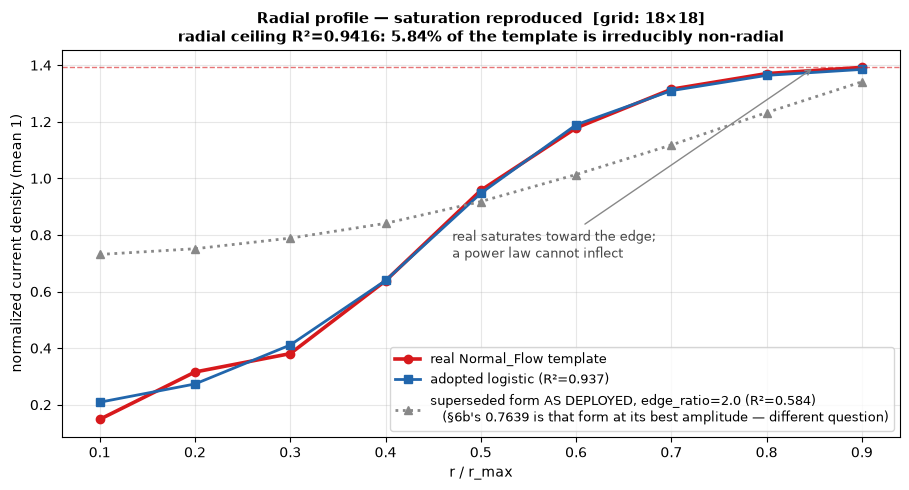

In [9]:
fig, ax = plt.subplots(figsize=(9.2, 5))
centers, rm, lm, sm = [], [], [], []
for b in range(1, 10):
    m = rb == b
    if m.sum():
        centers.append(b/10); rm.append(M.ravel()[m].mean())
        lm.append(S_log.ravel()[m].mean()); sm.append(S_sup.ravel()[m].mean())
ax.plot(centers, rm, "o-", color="#d7191c", lw=2.6, label=f"real Normal_Flow template")
ax.plot(centers, lm, "s-", color="#2166ac", lw=2.0, label=f"adopted logistic (R²={r2_log:.3f})")
ax.plot(centers, sm, "^:", color="#888888", lw=2.0,
        label=f"superseded form AS DEPLOYED, edge_ratio=2.0 (R\u00b2={r2_sup:.3f})\n"
              f"   (§6b's 0.7639 is that form at its best amplitude — different question)")
ax.axhline(rm[-1], color="#d7191c", ls="--", lw=1, alpha=0.6)
ax.annotate("real saturates toward the edge;\na power law cannot inflect",
            xy=(0.85, rm[-1]), xytext=(0.47, 0.72), fontsize=9.5, color="#444",
            arrowprops=dict(arrowstyle="->", color="#888"))
ax.set_xlabel("r / r_max"); ax.set_ylabel("normalized current density (mean 1)")
ax.set_title(f"Radial profile — saturation reproduced  [grid: 18×18]\n"
             f"radial ceiling R²={ceiling:.4f}: {100*(1-ceiling):.2f}% of the template is irreducibly non-radial",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "nb03_radial_profile.png"), dpi=150, bbox_inches="tight")
plt.show()

---
# Part 2 — Generator output demonstration

## ⚠️ DEMONSTRATION, NOT VALIDATION

Everything below shows that the generator *runs* and produces coherent
severity trajectories. The **fault-state spatial patterns are the superseded
diagonal-gradient interpolation** and are not validated by anything in this
notebook. Phase 3b reworks them. The caveat is repeated on every figure.

In [10]:
run = generate_labeled_run()   # defaults: logistic healthy family, 18x18
t = run["t_seconds"]; ft = run["active_fault_type"]; sev = run["severity"]
cvj = run["cv_j"]; nsb = run["near_seam_buffer"]; eps = run["episodes"]
hp = run["healthy_params"]

print(f"grid_shape     : {run['grid_shape']}")
print(f"healthy_model  : {run['healthy_model']}")
print(f"drawn cell     : " + ", ".join(f"{k}={v:.4f}" for k, v in hp.items()))
healthy = np.array([f is None for f in ft]) & ~nsb
print(f"\nhealthy CV(J)  : {cvj[healthy].mean():.4f}   [grid: {run['grid_shape'][0]}×{run['grid_shape'][1]}]"
      f"   (n={healthy.sum()} non-seam healthy timesteps)")
print(f"real band      : {REAL_BAND_18[0]:.4f} - {REAL_BAND_18[1]:.4f}   [grid: 18×18]")
for lab in ("starvation", "flooding", "drying"):
    e = [x for x in eps if x["fault_type"] == lab]
    print(f"{lab:<12}: {len(e)} episodes")

grid_shape     : (18, 18)
healthy_model  : logistic
drawn cell     : c=0.2290, r0=0.3235, w=0.0689, temporal_ratio=14.7003

healthy CV(J)  : 0.2499   [grid: 18×18]   (n=795 non-seam healthy timesteps)
real band      : 0.3247 - 0.3812   [grid: 18×18]
starvation  : 34 episodes
flooding    : 24 episodes
drying      : 9 episodes


In [11]:
def pick(label):
    cands = [e for e in eps if e["fault_type"] == label and e["precursor_window_s"] is not None]
    cands.sort(key=lambda e: e["achieved_peak_severity"], reverse=True)
    n = len(t)
    for ep in cands:
        i0 = int(np.searchsorted(t, ep["onset_start_s"])); i1 = int(np.searchsorted(t, ep["episode_end_s"]))
        span = np.arange(i0, min(i1 + 1, n))
        own = np.array([ft[i] == label for i in span])
        sub = span[own & (sev[span] > 0) & (sev[span] < CLASSIFICATION_THRESHOLD)]
        full = span[own]
        if not len(sub) or not len(full):
            continue
        mid = int(sub[np.argmax(sev[sub])]); fullest = int(full[np.argmax(sev[full])])
        h = next((k for d in range(n) for k in (i0 - d, i0 + d)
                  if 0 <= k < n and ft[k] is None and not nsb[k]), None)
        return ep, h, mid, fullest
    return None

sel = {}
print("representative timepoint availability (reported, not forced):\n")
for lab in ("starvation", "flooding", "drying"):
    res = pick(lab); sel[lab] = res
    if res is None:
        print(f"  {lab:<12} NO clean episode available -- skipped"); continue
    ep, h, mid, fl = res
    print(f"  {lab:<12} healthy t={t[h]:7.1f}s sev={sev[h]:.3f} | "
          f"mid-precursor t={t[mid]:7.1f}s sev={sev[mid]:.3f} (<{CLASSIFICATION_THRESHOLD}) | "
          f"full t={t[fl]:7.1f}s sev={sev[fl]:.3f}")
avail = sum(1 for v in sel.values() if v is not None) * 3
print(f"\n{avail}/9 combinations cleanly available.")

representative timepoint availability (reported, not forced):

  starvation   healthy t= 3015.0s sev=0.000 | mid-precursor t= 3016.0s sev=0.270 (<0.5) | full t= 3019.0s sev=0.987
  flooding     healthy t= 1431.0s sev=0.000 | mid-precursor t= 1385.0s sev=0.499 (<0.5) | full t= 1412.0s sev=0.991
  drying       healthy t= 3392.0s sev=0.000 | mid-precursor t= 3527.0s sev=0.499 (<0.5) | full t= 3738.0s sev=0.913

9/9 combinations cleanly available.


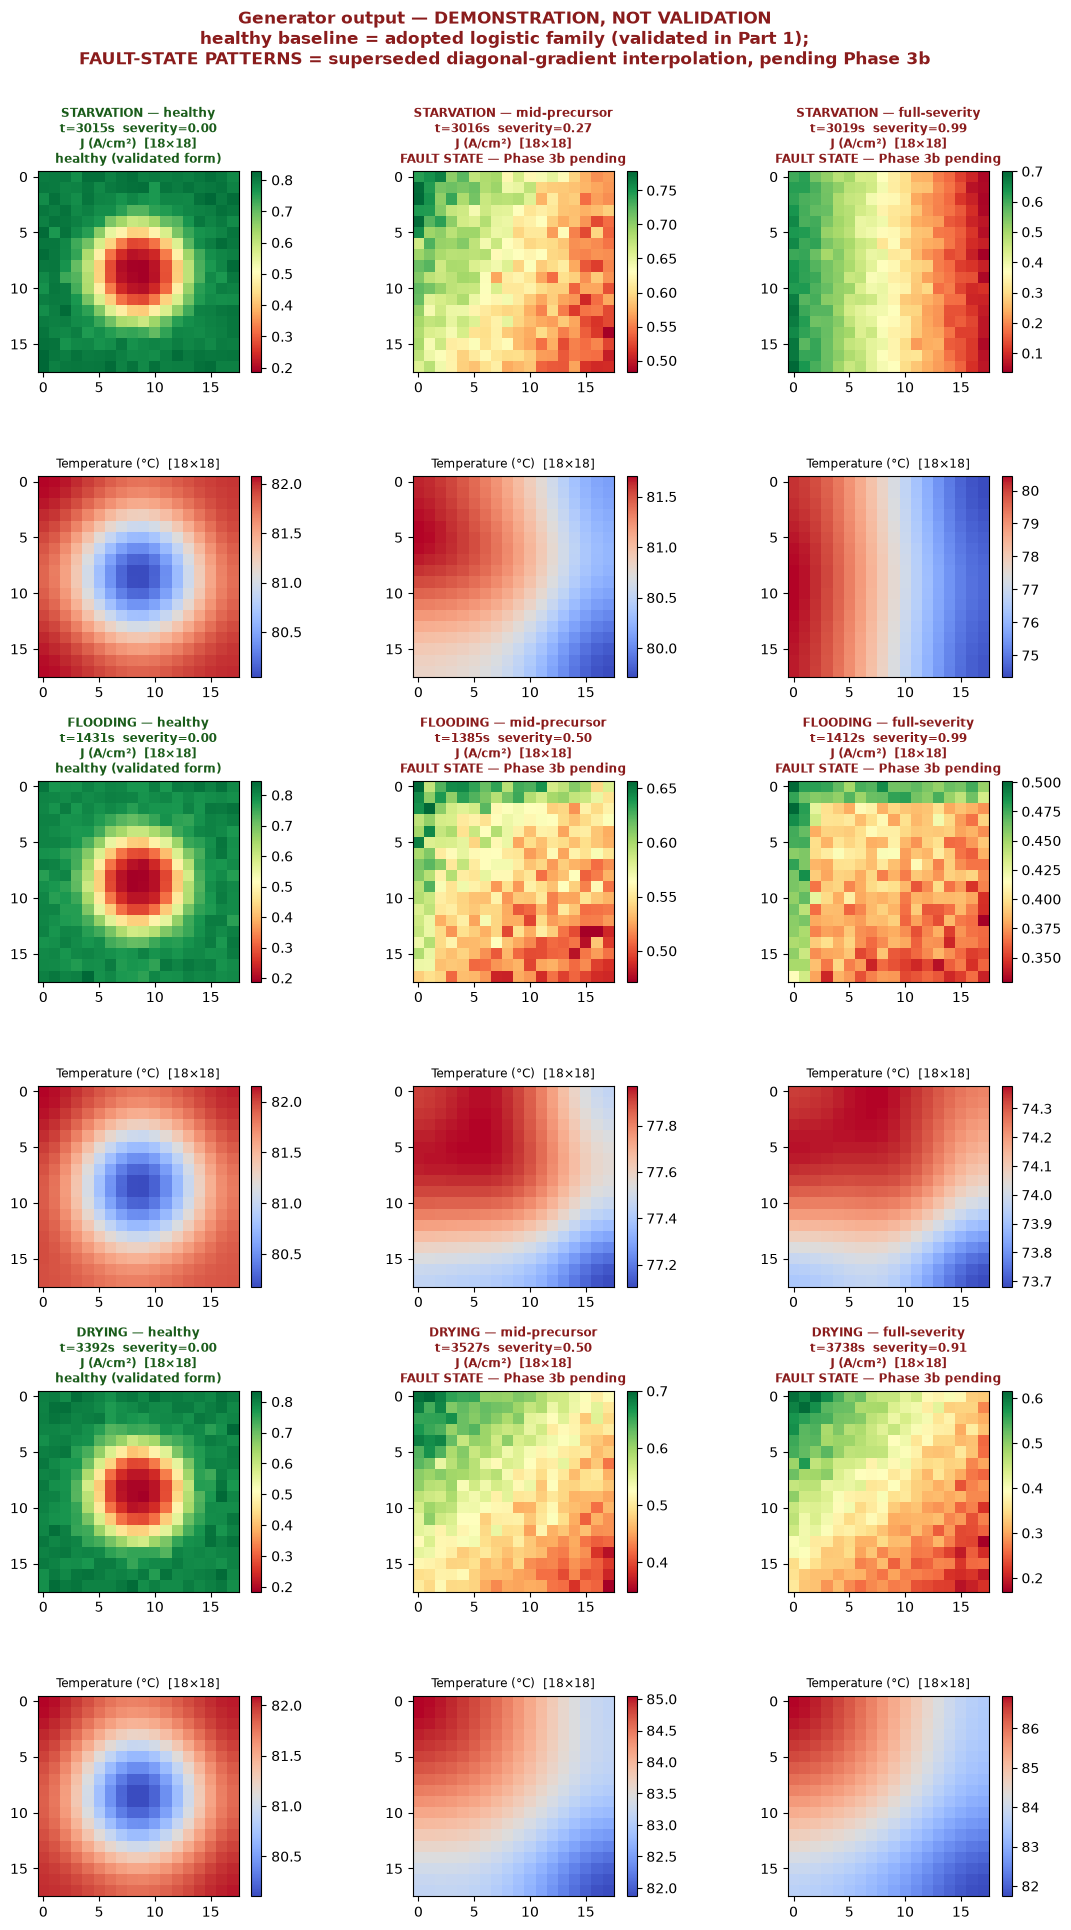

In [12]:
labels = [l for l in ("starvation", "flooding", "drying") if sel[l] is not None]
phases = ("healthy", "mid-precursor", "full-severity")
fig, axes = plt.subplots(2 * len(labels), 3, figsize=(11.5, 6.4 * len(labels)))
fig.suptitle("Generator output — DEMONSTRATION, NOT VALIDATION\n"
             "healthy baseline = adopted logistic family (validated in Part 1);\n"
             "FAULT-STATE PATTERNS = superseded diagonal-gradient interpolation, pending Phase 3b",
             fontsize=12, fontweight="bold", color="#8a1c1c", y=1.003)

for k, lab in enumerate(labels):
    ep, h, mid, fl = sel[lab]
    for col, (idx, ph) in enumerate(zip((h, mid, fl), phases)):
        jg, tg = run["current_grid"][idx], run["temp_grid"][idx]
        axj = axes[2*k, col]
        im = axj.imshow(jg, cmap="RdYlGn", aspect="equal")
        tag = "healthy (validated form)" if ph == "healthy" else "FAULT STATE — Phase 3b pending"
        axj.set_title(f"{lab.upper()} — {ph}\nt={t[idx]:.0f}s  severity={sev[idx]:.2f}\nJ (A/cm²)  [18×18]\n{tag}",
                      fontsize=8.5, fontweight="bold",
                      color=("#1a5c1a" if ph == "healthy" else "#8a1c1c"))
        plt.colorbar(im, ax=axj, fraction=0.046, pad=0.04)
        axt = axes[2*k+1, col]
        im2 = axt.imshow(tg, cmap="coolwarm", aspect="equal")
        axt.set_title("Temperature (°C)  [18×18]", fontsize=8.5)
        plt.colorbar(im2, ax=axt, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "nb03_spatial_by_phase.png"), dpi=150, bbox_inches="tight")
plt.show()

## 2.2 The `near_seam_buffer` windows — exclude these from any training set

The dynamic-only load trace concatenates **3 real driving segments** with
**2 artificial seams**. Fault state correctly never carries across a seam —
but because the three segments are similarly-shaped cycles that tend to both
start and end inside a qualifying high-load dwell, this produces a **hard
reset-then-reonset** at each seam: an episode active at one segment's last
sample is truncated there (severity drops straight to 0 instead of decaying),
and a fresh episode frequently onsets at the very first sample of the next
segment.

This is a **concatenation artifact, not a physical event**. A model trained
on it would learn a fault signature that does not exist in reality.

In [13]:
starts = np.flatnonzero(np.diff(np.concatenate(([0], nsb.astype(int)))) == 1)
ends   = np.flatnonzero(np.diff(np.concatenate((nsb.astype(int), [0]))) == -1)
seam_eps = [e for e in eps
            if nsb[max(0, int(np.searchsorted(t, e["onset_start_s"])) - 1):
                    min(len(t), int(np.searchsorted(t, e["episode_end_s"])) + 1)].any()]

print(f"near_seam_buffer: {int(nsb.sum())}/{len(nsb)} timesteps flagged "
      f"({100*nsb.sum()/len(nsb):.1f}% of the run), in {len(starts)} windows")
print(f"episodes overlapping a flagged window: {len(seam_eps)} of {len(eps)}")
for lab in ("starvation", "flooding", "drying"):
    k = sum(1 for e in seam_eps if e["fault_type"] == lab)
    print(f"   {lab:<12} {k} of {sum(1 for e in eps if e['fault_type']==lab)}")

seg = run["segment_id"]
bounds = np.flatnonzero(np.diff(seg) != 0)
print(f"\nseverity across each seam (the artifact, directly):")
for b in bounds:
    print(f"   t={t[b]:7.1f}s -> {t[b+1]:7.1f}s   severity {sev[b]:.4f} -> {sev[b+1]:.4f}"
          f"   fault {ft[b]} -> {ft[b+1]}")
print("\nEXCLUDE these windows from any training set built from this generator.")

near_seam_buffer: 362/3739 timesteps flagged (9.7% of the run), in 2 windows
episodes overlapping a flagged window: 6 of 67
   starvation   2 of 34
   flooding     0 of 24
   drying       4 of 9

severity across each seam (the artifact, directly):
   t= 1246.0s ->  1247.0s   severity 0.8852 -> 0.0000   fault drying -> None
   t= 2492.0s ->  2493.0s   severity 0.8449 -> 0.0000   fault drying -> None

EXCLUDE these windows from any training set built from this generator.


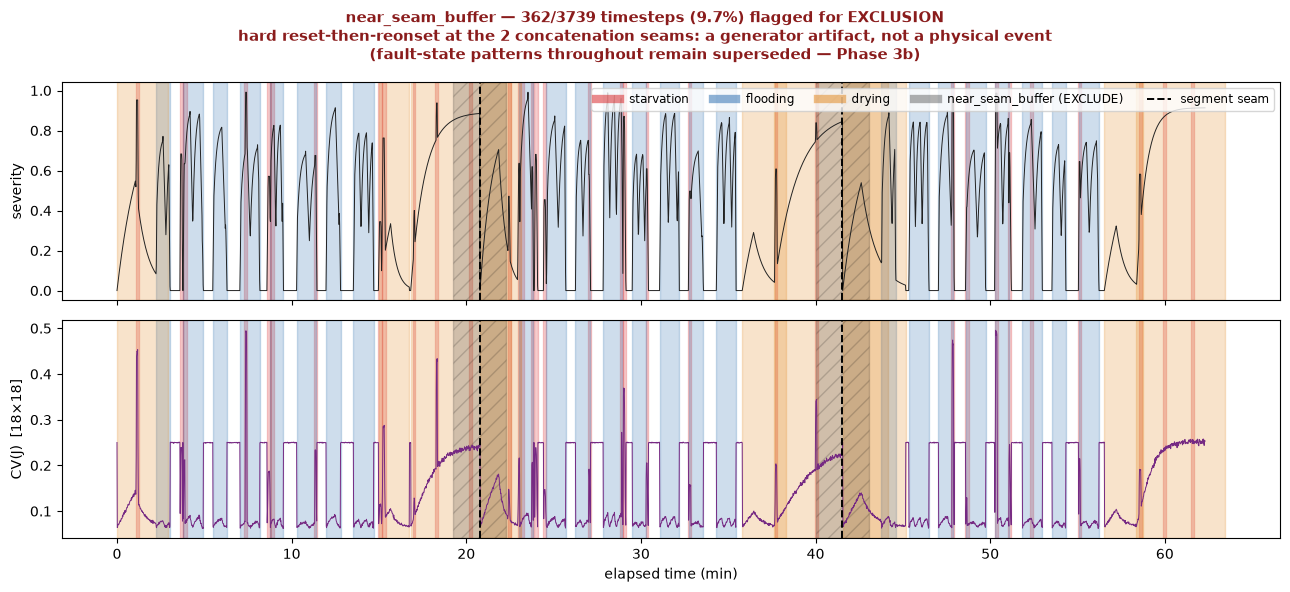

In [14]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
tm = t / 60.0
for ax in (a1, a2):
    for s0, s1 in zip(starts, ends):
        ax.axvspan(tm[s0], tm[s1], color="black", alpha=0.16, hatch="//", zorder=3)
    for e in eps:
        ax.axvspan(e["onset_start_s"]/60, e["episode_end_s"]/60,
                   color=FAULT_COLORS[e["fault_type"]], alpha=0.22, zorder=1)
    for b in bounds:
        ax.axvline(tm[b], color="k", lw=1.4, ls="--", zorder=5)
a1.plot(tm, sev, color="#222", lw=0.7, zorder=4)
a1.set_ylabel("severity")
a2.plot(tm, cvj, color="#762a83", lw=0.7, zorder=4)
a2.set_ylabel("CV(J)  [18×18]"); a2.set_xlabel("elapsed time (min)")
handles = [plt.Line2D([0],[0], color=c, lw=6, alpha=0.5, label=k) for k, c in FAULT_COLORS.items()]
handles.append(plt.Line2D([0],[0], color="black", lw=6, alpha=0.3, label="near_seam_buffer (EXCLUDE)"))
handles.append(plt.Line2D([0],[0], color="k", lw=1.4, ls="--", label="segment seam"))
a1.legend(handles=handles, fontsize=8.5, ncol=5, loc="upper right")
fig.suptitle(f"near_seam_buffer — {int(nsb.sum())}/{len(nsb)} timesteps ({100*nsb.sum()/len(nsb):.1f}%) flagged for EXCLUSION\n"
             "hard reset-then-reonset at the 2 concatenation seams: a generator artifact, not a physical event\n"
             "(fault-state patterns throughout remain superseded — Phase 3b)",
             fontsize=11, fontweight="bold", color="#8a1c1c")
plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "nb03_near_seam_buffer.png"), dpi=150, bbox_inches="tight")
plt.show()

---
# What is real, what is literature-grounded, what is tuned or assumed

Carried forward verbatim in substance from `docs/real_data_notes.md` and
`docs/synthetic_generator_notes.md`. Nothing below should be read as more
validated than its category allows.

## Real — measured, not assumed
- **The load trace**: timing, shape, and the 3-segment/2-seam structure, from
  the real Normal_Flow FC-DLC recording.
- **Trigger thresholds** (0.02/s ramp; 0.10/0.40 dwell; 10 s minimum) — from
  that trace's own measured distributions.
- **The radial healthy structure**: r = 0.936 vs distance-from-centre,
  quadratic R² = 0.906, row/column correlations ≈ 0, reproducing across **all
  four sessions** with cross-session template correlation r ≥ 0.976. This is
  the strongest empirical result the project has, and it is what justifies a
  radial template rather than a flow-path gradient.
- **CV(J)'s load-invariance** and the real CV(J) band (0.3247–0.3812 @18×18).
- **The radial ceiling** R² = 0.9416 — 5.84% of the real template is
  irreducibly non-radial.

## Literature-grounded, not independently validated here
- *Relative* fault onset-speed ordering: starvation fast (seconds), flooding
  fast-but-oscillatory (tens of seconds), drying slow (tens of seconds to
  minutes), and the mechanisms motivating each shape.
- The fault spatial pattern *locations* — notebook 01's grounding, **carried
  over unchanged and superseded for the healthy baseline only**. No
  fault-labelled real data exists for this cell, so none of it is validated
  against measurement.

## Tuned or assumed — and the asymmetry matters
- **Form choice is data-dependent (§6d).** The logistic was selected *because
  the real templates inflect and saturate*. That is a **stronger** dependence
  on the validation data than the superseded `p = 2` ever had — p=2 at least
  carried an independent argument, though §5d shows it was invalid. This is
  not softened: Phase 5 can test parameter-value generalization inside an
  assumed form, but **can no longer claim independence of the real data's
  structure.**
- **`c` vs `r0`/`w` asymmetry.** `c` has thin but real empirical content
  (1.48× observed cross-session variation). `r0` and `w` are fixed to within
  5% and 2% in *every* session available — the data fixes a value, not a
  range. **Their ranges are assumption, not observation.**
- **§6h standing instruction**: any Phase 5 finding whose conclusion depends
  on the breadth of `r0` or `w` must be marked, *at the point it is stated*,
  as resting on assumed rather than observed variability. A result surviving
  only because `r0`/`w` were ranged widely is a statement about an
  assumption. The converse holds too: a failure only at extreme `r0`/`w` is a
  failure against assumed conditions.
- **Sampling skew is deliberate.** Uniform sampling puts most of the family
  below the real minimum. A more uniform cell has a lower CV(J) baseline, so
  a threshold that must stay quiet across this family has **less** headroom —
  the skew makes false-alarm avoidance **harder**. A model quiet across this
  family makes a stronger claim than one validated on a family centred on
  real. Log-uniform sampling was rejected for exactly that reason.
- **All fault onset-timescale constants** (the [2,5] s stage draws, flooding's
  cycle period and partial-drain floor, drying's time constants, every
  severity_target range) are engineering choices matching only a qualitative
  description. Each is labelled `# CALIBRATION CHOICE` at its definition.

## Confounds that cannot be resolved with this dataset
- **The centre-depth split is perfectly confounded.** `c` clusters as
  {Feb 9, Feb 11} ≈ 0.139 and {Feb 17, Feb 18} ≈ 0.203 — simultaneously a
  split by **H₂ routing** and by **session block** six days apart. Both
  explanations fit exactly.
- **The missing experiment**, named so it is not mistaken for an oversight:
  the dataset contains *no repeat of any routing across the two session
  blocks*, and *no block containing both routings*. Either alone would settle
  it — a second `Normal_Flow` run in the Feb 17–18 block reading `c ≈ 0.20`
  would mean the sitting; `c ≈ 0.139` would mean the routing. Neither exists.
- The clamping-torque hypothesis is therefore **live, not rejected**. An
  earlier rejection was an artifact of testing it through an unidentifiable
  parameter — absence of spread in a parameter that cannot carry signal is
  not evidence of absence.

## Phase 3b — what this notebook does not cover
Fault-state spatial patterns remain the superseded diagonal-gradient
interpolation. Phase 3b reworks them with the same treatment the healthy form
received: literature grounding, capability check, identifiability check, and
an honest statement of data-dependence. Note that Phase 3b **inherits a
partially-generalized temperature path** — the centre-bias profile and
smoothing length are already resolution-aware (§9), while every other
temperature constant remains notebook-01-derived.